In [ ]:


import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (891, 15)

First 5 rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [ ]:



print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nSurvival Distribution:")
print(df["survived"].value_counts())

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape:
(891, 15)

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone     

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:



from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Select useful features and target
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
target = "survived"

X = df[features].copy()
y = df[target].copy()

# Split data BEFORE fitting preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Separate numeric and categorical columns
numeric_features = ["pclass", "age", "sibsp", "parch", "fare"]
categorical_features = ["sex", "embarked"]

# Process numerical data
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit only on training data; transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("Missing values in training data after preprocessing:",
      int(__import__("numpy").isnan(X_train_processed.toarray()
      if hasattr(X_train_processed, "toarray")
      else X_train_processed).sum()))
print("Preprocessing completed successfully!")

Training data shape: (712, 10)
Testing data shape: (179, 10)
Missing values in training data after preprocessing: 0
Preprocessing completed successfully!


In [ ]:



from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(max_iter=1000, random_state=42)

# Train using preprocessed training data
model.fit(X_train_processed, y_train)

print("Model training completed successfully!")

print("Training samples:", X_train_processed.shape[0])
print("Testing samples:", X_test_processed.shape[0])
print("Model used:", type(model).__name__)

Model training completed successfully!
Training samples: 712
Testing samples: 179
Model used: LogisticRegression


In [ ]:



from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict on unseen test data
y_pred = model.predict(X_test_processed)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8045
Precision: 0.7931
Recall: 0.6667
F1-score: 0.7244

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Confusion Matrix:
[[98 12]
 [23 46]]


In [ ]:



from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and model into one pipeline
full_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Cross-validation on the training data only
cv_scores = cross_val_score(
    full_model, X_train, y_train, cv=5, scoring="accuracy"
)

print("Cross-validation scores:", cv_scores.round(4))
print("Mean CV accuracy:", round(cv_scores.mean(), 4))
print("Standard deviation:", round(cv_scores.std(), 4))

Cross-validation scores: [0.7902 0.7622 0.8028 0.8169 0.8099]
Mean CV accuracy: 0.7964
Standard deviation: 0.0192


In [ ]:



from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train_processed, y_train)

baseline_pred = baseline.predict(X_test_processed)
model_pred = model.predict(X_test_processed)

print("Baseline accuracy:",
      round(accuracy_score(y_test, baseline_pred), 4))

print("Logistic Regression accuracy:",
      round(accuracy_score(y_test, model_pred), 4))

Baseline accuracy: 0.6145
Logistic Regression accuracy: 0.8045


In [ ]:



import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Baseline Accuracy",
        "Mean Cross-Validation Accuracy"
    ],
    "Score": [
        accuracy_score(y_test, model.predict(X_test_processed)),
        precision_score(y_test, model.predict(X_test_processed), zero_division=0),
        recall_score(y_test, model.predict(X_test_processed), zero_division=0),
        f1_score(y_test, model.predict(X_test_processed), zero_division=0),
        accuracy_score(y_test, baseline.predict(X_test_processed)),
        cv_scores.mean()
    ]
})

results["Score"] = results["Score"].round(4)

display(results)

print("Project: Titanic Survival Prediction")
print("Algorithm: Logistic Regression")
print("Features used:", features)
print("Dataset rows:", len(df))

,Metric,Score
0,Test Accuracy,0.8045
1,Precision,0.7931
2,Recall,0.6667
3,F1-Score,0.7244
4,Baseline Accuracy,0.6145
5,Mean Cross-Validation Accuracy,0.7964


Project: Titanic Survival Prediction
Algorithm: Logistic Regression
Features used: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
Dataset rows: 891


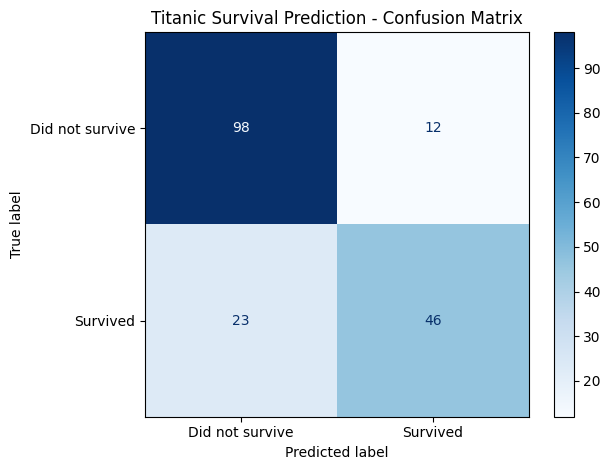

In [ ]:


import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    model.predict(X_test_processed),
    display_labels=["Did not survive", "Survived"],
    cmap="Blues"
)

plt.title("Titanic Survival Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()